# 시군구 응급의료 접근성 × 복지 취약: 이중 취약지역과 유형화

- 입력: `data/processed/sigungu_table.csv` (229개 시군구, `python -m src.build_table`)
- 출력: `outputs/` 에 그림(png)과 표(csv)
- 기준 시점: 인구·복지 2025년 12월, 응급의료기관 2026-11-04 수집 (데이터 한계는 `data/README.md`)

In [1]:
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 한글 폰트: OS 기본 폰트 사용
plt.rc('font', family={'Windows': 'Malgun Gothic', 'Darwin': 'AppleGothic'}.get(platform.system(), 'NanumGothic'))
plt.rcParams['axes.unicode_minus'] = False

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'processed' / 'sigungu_table.csv'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

K = 3         # 클러스터 수: 아래 엘보우·실루엣 그래프를 보고 직접 정한다
SEED = 195    # legacy 분석과 동일
TOP = 0.25    # 이중 취약: 두 점수 모두 상위 25%
NEAR = 0.40   # 준 이중 취약: 한쪽 상위 TOP + 다른 쪽 상위 NEAR
SKEW_LOG = 1  # 왜도가 이보다 크면 log1p 변환

# 클러스터 라벨 (수동). 클러스터 번호는 접근성 취약 점수 평균이 낮은 순서로 0, 1, 2, ... 로 다시 매긴다
CLUSTER_LABELS = {
    0: '도시·접근성 양호',
    1: '고령 농촌·응급센터 원거리',
    2: '고령 농촌·응급의료 취약',
}

INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e5e4df'
DOUBLE, NEAR_C, BASE = '#eb6834', '#2a78d6', '#c9c8c1'

## 1. 피처

| 그룹 | 피처 | 정의 | 취약 방향 | 점수 | 클러스터링 |
|---|---|---|---|---|---|
| 복지 | 고령인구비율 | 65세 이상 인구 / 총인구 | 클수록 | O | 복지취약_종합으로 |
| 복지 | 독거노인비율 | 65세 이상 1인세대 / 65세 이상 인구 | 클수록 | O | 복지취약_종합으로 |
| 복지 | 장애인비율 | 등록장애인 / 총인구 | 클수록 | O | 복지취약_종합으로 |
| 접근성 | 최근접_응급의료기관_km | 기준점 → 가장 가까운 응급의료기관 직선거리 | 클수록 | O | O |
| 접근성 | 최근접_권역지역센터_km | 기준점 → 가장 가까운 권역·지역응급의료센터 | 클수록 | O | O |
| 접근성 | 반경30km_응급의료기관수 | 기준점 반경 30km 안 응급의료기관 수 | **작을수록** (부호 반대) | O | O |

- **제외**: `인구10만명당_응급의료기관수` (테이블에는 유지). 시군구 경계 안의 기관만 세서 소면적·고밀도 도심을 과소평가한다(예: 서울 마포구 0곳). 기초생활수급자는 시군구 단위 공개 통계가 없다.
- **복지취약_종합**: 복지 3개 피처는 서로 상관이 0.8~0.95로 높다. 클러스터링에서 복지 축이 3배 무게를 받지 않도록 z점수 평균 1개로 합친다.

In [2]:
t = pd.read_csv(DATA, dtype={'code': str}).set_index('code').fillna({'시군구': ''})
t['고령인구비율'] = t['65세이상인구'] / t['총인구']
t['지역'] = (t['시도'] + ' ' + t['시군구']).str.strip()

WELFARE = ['고령인구비율', '독거노인비율', '장애인비율']
ACCESS = ['최근접_응급의료기관_km', '최근접_권역지역센터_km', '반경30km_응급의료기관수']
FEATURES = WELFARE + ACCESS
REVERSE = ['반경30km_응급의료기관수']  # 클수록 좋은 지표 -> 부호 반대

assert t[FEATURES].notna().all().all(), t[t[FEATURES].isna().any(axis=1)]
print(f'분석 대상: {len(t)}개 시군구')
t[FEATURES].describe().round(3).T

분석 대상: 229개 시군구


,count,mean,std,min,25%,50%,75%,max
고령인구비율,229.0,0.278,0.095,0.116,0.198,0.257,0.360,0.492
독거노인비율,229.0,0.324,0.057,0.166,0.285,0.321,0.371,0.445
장애인비율,229.0,0.068,0.024,0.025,0.048,0.063,0.088,0.121
최근접_응급의료기관_km,229.0,3.074,5.307,0.067,0.636,1.139,2.302,28.030
최근접_권역지역센터_km,229.0,13.046,17.599,0.167,1.291,3.632,22.145,153.829
반경30km_응급의료기관수,229.0,29.260,33.842,1.000,6.000,11.000,37.000,116.000


## 2. 전처리: 왜도 → log1p, 방향 통일, 표준화

오른쪽으로 치우친 피처(왜도 > `SKEW_LOG`)는 log1p로 변환한다. 그다음 기관 수 지표는 부호를 바꿔 모든 피처가 "클수록 취약"이 되게 맞추고, 표준화한다.

In [3]:
skew = t[FEATURES].skew()
LOG = skew[skew > SKEW_LOG].index.tolist()

X = t[FEATURES].copy()
X[LOG] = np.log1p(X[LOG])
X[REVERSE] = -X[REVERSE]
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=FEATURES)

print('log1p 변환:', LOG)
pd.DataFrame({'왜도(원본)': skew, 'log1p': skew.index.isin(LOG), '왜도(변환 후)': X.skew()}).round(2)

log1p 변환: ['최근접_응급의료기관_km', '최근접_권역지역센터_km', '반경30km_응급의료기관수']


,왜도(원본),log1p,왜도(변환 후)
고령인구비율,0.40,False,0.40
독거노인비율,-0.20,False,-0.20
장애인비율,0.38,False,0.38
최근접_응급의료기관_km,2.90,True,1.53
최근접_권역지역센터_km,3.10,True,0.28
반경30km_응급의료기관수,1.28,True,-0.19


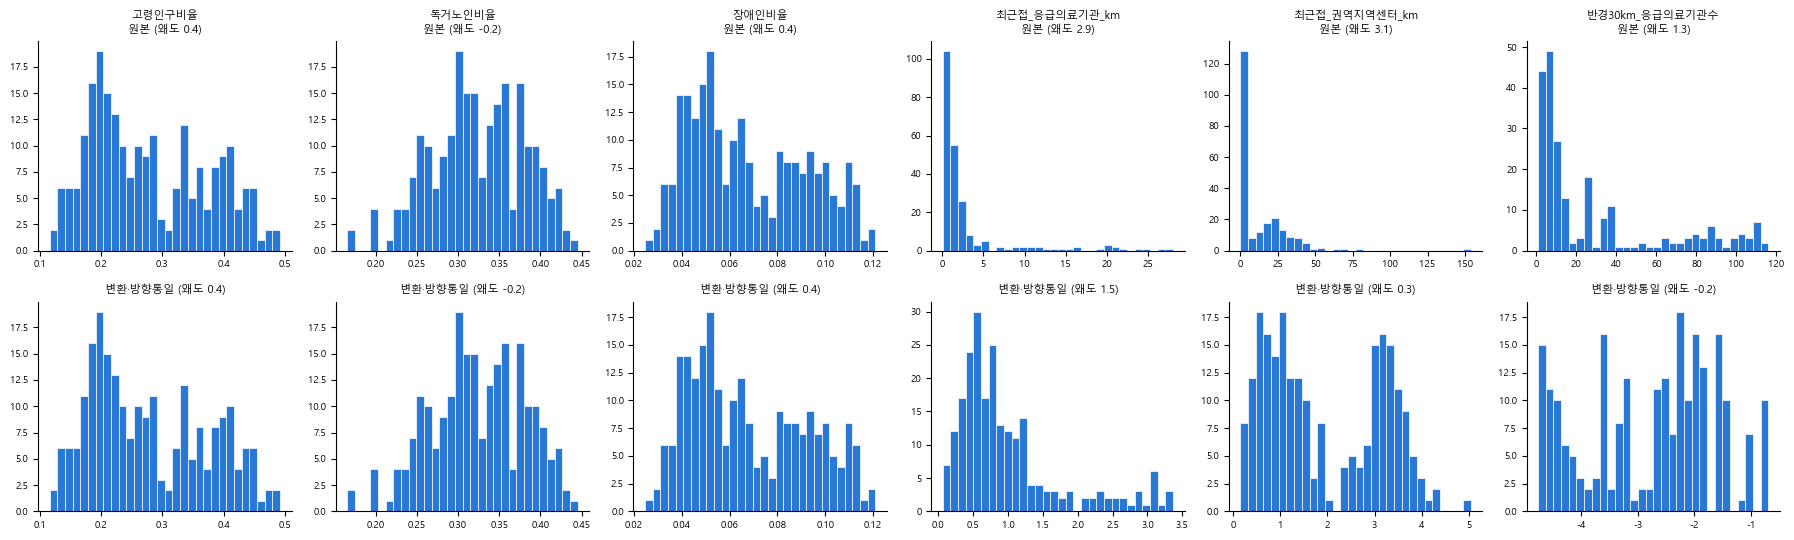

In [4]:
fig, axes = plt.subplots(2, len(FEATURES), figsize=(3 * len(FEATURES), 5.5))
for i, f in enumerate(FEATURES):
    for row, (data, title) in enumerate([(t[f], '원본'), (X[f], '변환·방향통일')]):
        ax = axes[row, i]
        ax.hist(data, bins=30, color='#2a78d6', edgecolor='white', linewidth=0.5)
        ax.set_title(f'{f}\n{title} (왜도 {data.skew():.1f})' if row == 0 else f'{title} (왜도 {data.skew():.1f})', fontsize=8)
        ax.tick_params(labelsize=7)
        ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'feature_distributions.png', dpi=200)
plt.show()

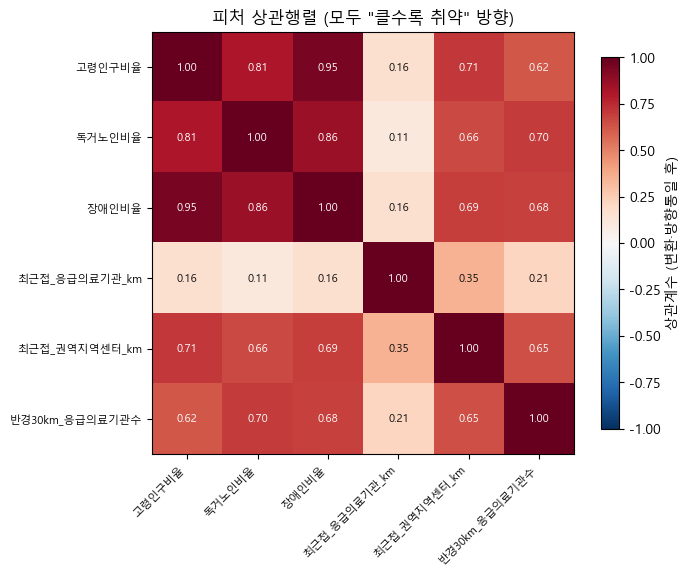

상관 높은 쌍 (|r| ≥ 0.7):
고령인구비율  장애인비율            0.95
독거노인비율  장애인비율            0.86
고령인구비율  독거노인비율           0.81
        최근접_권역지역센터_km    0.71


In [5]:
corr = Z.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8, label='상관계수 (변환·방향통일 후)')
ax.set_title('피처 상관행렬 (모두 "클수록 취약" 방향)')
fig.tight_layout()
fig.savefig(OUT / 'feature_correlation.png', dpi=200)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print('상관 높은 쌍 (|r| ≥ 0.7):')
print(pairs[pairs.abs() >= 0.7].round(2).to_string())

## 3. 취약 점수와 이중 취약지역

- **접근성 취약 점수**, **복지 취약 점수**: 각 그룹 피처의 백분위 순위(0~100, 방향 통일 후)를 평균한다. 순위 기반이라 log 변환이나 극단값에 영향을 받지 않는다.
- **이중 취약**: 두 점수가 모두 상위 `TOP`(25%)
- **준 이중 취약**: 한쪽이 상위 `TOP`(25%), 다른 쪽이 상위 `NEAR`(40%) (이중 취약 제외)

In [6]:
pct = X.rank(pct=True) * 100
t['접근성취약점수'] = pct[ACCESS].mean(axis=1)
t['복지취약점수'] = pct[WELFARE].mean(axis=1)
t['접근성순위'] = t['접근성취약점수'].rank(ascending=False, method='min').astype(int)
t['복지순위'] = t['복지취약점수'].rank(ascending=False, method='min').astype(int)

cut = {q: (t['접근성취약점수'].quantile(1 - q), t['복지취약점수'].quantile(1 - q)) for q in (TOP, NEAR)}
a_top, w_top = (t['접근성취약점수'] >= cut[TOP][0]), (t['복지취약점수'] >= cut[TOP][1])
a_near, w_near = (t['접근성취약점수'] >= cut[NEAR][0]), (t['복지취약점수'] >= cut[NEAR][1])
t['등급'] = np.select([a_top & w_top, (a_top & w_near) | (w_top & a_near)], ['이중 취약', '준 이중 취약'], '')

SCORE_COLS = ['시도', '시군구', '등급', '접근성취약점수', '복지취약점수', '접근성순위', '복지순위']
dv = (t[t['등급'] != ''].assign(합산점수=lambda d: d['접근성취약점수'] + d['복지취약점수'])
      .sort_values(['등급', '합산점수'], ascending=[True, False]))
dv[SCORE_COLS + ['합산점수'] + FEATURES].round(3).to_csv(OUT / 'double_vulnerable.csv', encoding='utf-8-sig')

print(f'상위 {TOP:.0%} 기준: 접근성 ≥ {cut[TOP][0]:.1f}, 복지 ≥ {cut[TOP][1]:.1f} / '
      f'상위 {NEAR:.0%} 기준: 접근성 ≥ {cut[NEAR][0]:.1f}, 복지 ≥ {cut[NEAR][1]:.1f}')
print(dv['등급'].value_counts().to_string())
print(dv.pivot_table(index='시도', columns='등급', values='시군구', aggfunc='size', fill_value=0).to_string())
dv[SCORE_COLS + FEATURES].round(2)

상위 25% 기준: 접근성 ≥ 64.9, 복지 ≥ 75.5 / 상위 40% 기준: 접근성 ≥ 56.2, 복지 ≥ 60.9
등급
이중 취약      30
준 이중 취약    29
등급  이중 취약  준 이중 취약
시도                
강원      3        4
경기      0        3
경남      2        6
경북      8        5
대구      1        0
인천      1        0
전남      8        3
전북      3        4
충남      2        3
충북      2        1


,시도,시군구,등급,접근성취약점수,복지취약점수,접근성순위,복지순위,고령인구비율,독거노인비율,장애인비율,최근접_응급의료기관_km,최근접_권역지역센터_km,반경30km_응급의료기관수
code,,,,,,,,,,,,,
47770,경북,영덕군,이중 취약,98.18,94.91,2,8,0.45,0.42,0.11,28.03,44.14,1.00
47760,경북,영양군,이중 취약,96.72,89.37,3,20,0.43,0.37,0.11,26.74,36.53,1.00
46770,전남,고흥군,이중 취약,85.66,96.65,14,5,0.47,0.41,0.11,2.43,39.16,4.00
47730,경북,의성군,이중 취약,85.66,95.92,14,7,0.49,0.39,0.12,21.60,21.60,4.00
47920,경북,봉화군,이중 취약,91.63,89.37,9,20,0.45,0.37,0.11,12.45,36.26,3.00
46890,전남,완도군,이중 취약,95.34,82.24,5,39,0.39,0.38,0.09,10.97,65.62,1.65
27720,대구,군위군,이중 취약,85.95,90.83,13,16,0.49,0.37,0.11,20.47,23.12,4.00
46860,전남,함평군,이중 취약,78.82,97.09,20,2,0.43,0.43,0.12,8.61,28.60,8.00
46780,전남,보성군,이중 취약,78.24,96.94,21,3,0.45,0.42,0.11,2.27,32.72,6.00


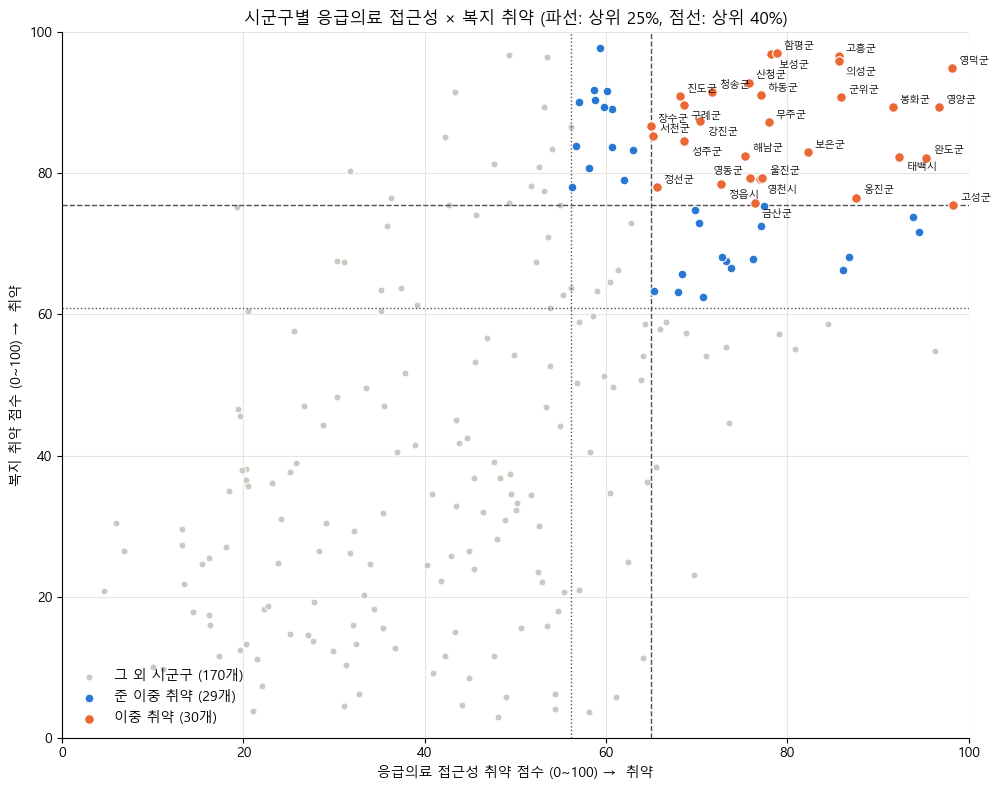

이름표 생략: 없음


In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
groups = [('', BASE, 26, '그 외 시군구'), ('준 이중 취약', NEAR_C, 40, '준 이중 취약'), ('이중 취약', DOUBLE, 48, '이중 취약')]
for g, color, size, name in groups:
    d = t[t['등급'] == g]
    ax.scatter(d['접근성취약점수'], d['복지취약점수'], s=size, color=color, edgecolor='white', lw=0.8,
               label=f'{name} ({len(d)}개)', zorder=3 if g else 2)
for q, ls in [(TOP, '--'), (NEAR, ':')]:
    ax.axvline(cut[q][0], color=MUTED, ls=ls, lw=1)
    ax.axhline(cut[q][1], color=MUTED, ls=ls, lw=1)
ax.set(xlabel='응급의료 접근성 취약 점수 (0~100) →  취약', ylabel='복지 취약 점수 (0~100) →  취약',
       title=f'시군구별 응급의료 접근성 × 복지 취약 (파선: 상위 {TOP:.0%}, 점선: 상위 {NEAR:.0%})',
       xlim=(0, 100), ylim=(0, 100))
ax.grid(color=GRID, lw=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower left', frameon=False)
fig.tight_layout()

# 이름표: 이중 취약지역만. 겹치지 않는 위치를 차례로 시도, 다 겹치면 생략 (준 이중 취약 포함 전체 목록은 double_vulnerable.csv)
renderer, placed, skipped = fig.canvas.get_renderer(), [], []
for _, r in dv[dv['등급'] == '이중 취약'].iterrows():
    for dx, dy, ha in [(5, 3, 'left'), (5, -10, 'left'), (-5, 3, 'right'), (-5, -10, 'right'), (0, 8, 'center'), (0, -15, 'center')]:
        txt = ax.annotate(r['시군구'] or r['시도'], (r['접근성취약점수'], r['복지취약점수']), xytext=(dx, dy),
                          textcoords='offset points', ha=ha, fontsize=7.5, color=INK)
        box = txt.get_window_extent(renderer)
        if not any(box.overlaps(b) for b in placed):
            placed.append(box)
            break
        txt.remove()
    else:
        skipped.append(r['지역'])
fig.savefig(OUT / 'double_vulnerable_scatter.png', dpi=200)
plt.show()
print('이름표 생략:', skipped or '없음')

## 4. 클러스터링 (K-means)

- 피처 4개: **복지취약_종합**(복지 3개 z점수 평균), 최근접_응급의료기관_km, 최근접_권역지역센터_km, 반경30km_응급의료기관수
- 모두 log1p·방향 통일 후 다시 표준화해서 같은 무게로 쓴다.
- k=2~6을 비교한다. 맨 위 셀의 `K` 가 현재 값이다(점선).

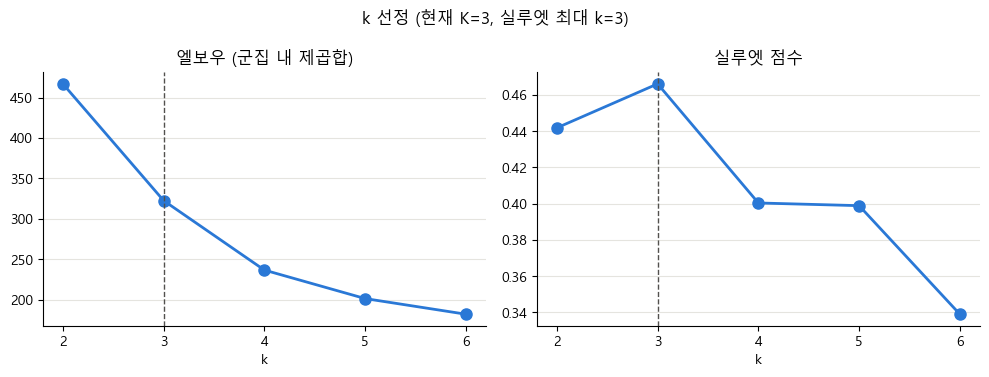

k,2,3,4,5,6
inertia,466.970,322.536,236.564,201.303,181.960
silhouette,0.442,0.466,0.400,0.399,0.339


In [8]:
C = Z[ACCESS].copy()
C.insert(0, '복지취약_종합', Z[WELFARE].mean(axis=1))
CLUSTER_FEATURES = C.columns.tolist()
C = pd.DataFrame(StandardScaler().fit_transform(C), index=C.index, columns=CLUSTER_FEATURES)

ks = list(range(2, 7))
models = {k: KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(C) for k in ks}
inertia = [models[k].inertia_ for k in ks]
sil = [silhouette_score(C, models[k].labels_) for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, y, title in [(axes[0], inertia, '엘보우 (군집 내 제곱합)'), (axes[1], sil, '실루엣 점수')]:
    ax.plot(ks, y, color='#2a78d6', lw=2, marker='o', ms=8)
    ax.axvline(K, color=MUTED, ls='--', lw=1)
    ax.set(title=title, xlabel='k', xticks=ks)
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'k 선정 (현재 K={K}, 실루엣 최대 k={ks[int(np.argmax(sil))]})')
fig.tight_layout()
fig.savefig(OUT / 'k_selection.png', dpi=200)
plt.show()
pd.DataFrame({'k': ks, 'inertia': inertia, 'silhouette': sil}).round(3).set_index('k').T

In [9]:
km = models[K]
# 번호를 접근성 취약 점수 평균이 낮은 순으로 다시 매겨 실행할 때마다 같은 번호가 되게 한다
order = pd.Series(km.labels_, index=t.index).to_frame('c').join(t['접근성취약점수']).groupby('c')['접근성취약점수'].mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
t['클러스터'] = pd.Series(km.labels_, index=t.index).map(remap)
centers = pd.DataFrame(km.cluster_centers_, columns=CLUSTER_FEATURES).rename(index=remap).sort_index()
t['유형'] = t['클러스터'].map(CLUSTER_LABELS).fillna('(라벨 없음)')

profile = t.groupby('클러스터')[FEATURES + ['접근성취약점수', '복지취약점수']].median()
profile.insert(0, '시군구수', t['클러스터'].value_counts().sort_index())
profile.insert(0, '유형', pd.Series(CLUSTER_LABELS).reindex(profile.index))
profile['이중취약수'] = t[t['등급'] == '이중 취약'].groupby('클러스터').size().reindex(profile.index, fill_value=0)
profile['준이중취약수'] = t[t['등급'] == '준 이중 취약'].groupby('클러스터').size().reindex(profile.index, fill_value=0)
profile.round(3).to_csv(OUT / 'cluster_profile.csv', encoding='utf-8-sig')
print('클러스터별 중앙값')
profile.round(2)

클러스터별 중앙값


,유형,시군구수,고령인구비율,독거노인비율,장애인비율,최근접_응급의료기관_km,최근접_권역지역센터_km,반경30km_응급의료기관수,접근성취약점수,복지취약점수,이중취약수,준이중취약수
클러스터,,,,,,,,,,,,
0,도시·접근성 양호,129,0.21,0.29,0.05,1.10,1.57,35.0,35.52,29.55,0,0
1,고령 농촌·응급센터 원거리,71,0.38,0.38,0.09,0.80,24.21,6.0,61.35,79.04,16,21
2,고령 농촌·응급의료 취약,29,0.35,0.36,0.08,14.95,23.12,4.0,84.50,73.80,14,8


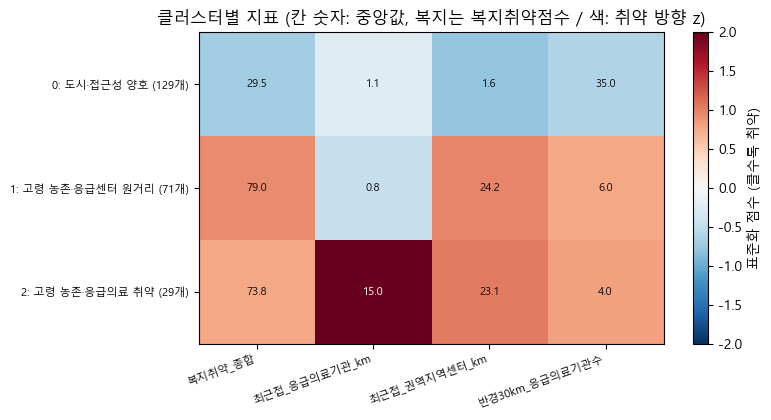

In [10]:
fig, ax = plt.subplots(figsize=(8, 0.9 * K + 1.6))
im = ax.imshow(centers, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
shown = {'복지취약_종합': '복지취약점수'} | {f: f for f in ACCESS}
ax.set_xticks(range(len(CLUSTER_FEATURES)), CLUSTER_FEATURES, rotation=20, ha='right', fontsize=8)
ax.set_yticks(range(K), [f'{c}: {CLUSTER_LABELS.get(c, "")} ({(t["클러스터"] == c).sum()}개)' for c in range(K)], fontsize=8)
for i in range(K):
    for j, f in enumerate(CLUSTER_FEATURES):
        ax.text(j, i, f'{profile.loc[i, shown[f]]:.1f}', ha='center', va='center', fontsize=8,
                color='white' if abs(centers.iloc[i, j]) > 1.2 else INK)
fig.colorbar(im, ax=ax, label='표준화 점수 (클수록 취약)')
ax.set_title('클러스터별 지표 (칸 숫자: 중앙값, 복지는 복지취약점수 / 색: 취약 방향 z)')
fig.tight_layout()
fig.savefig(OUT / 'cluster_heatmap.png', dpi=200)
plt.show()

In [11]:
# 대표 시군구: 클러스터 중심에 가장 가까운 5개
t['중심거리'] = np.linalg.norm(C.values - centers.values[t['클러스터'].values], axis=1)
rep = (t.sort_values('중심거리').groupby('클러스터').head(5)
       .groupby('클러스터')['지역'].apply(', '.join).rename('대표 시군구 (중심에 가까운 5개)'))
pd.concat([pd.Series(CLUSTER_LABELS, name='유형'), rep], axis=1)

,유형,대표 시군구 (중심에 가까운 5개)
0,도시·접근성 양호,"광주 서구, 부산 해운대구, 대구 북구, 부산 연제구, 광주 북구"
1,고령 농촌·응급센터 원거리,"충남 청양군, 경남 남해군, 강원 영월군, 전북 순창군, 충남 부여군"
2,고령 농촌·응급의료 취약,"충북 음성군, 경기 가평군, 경남 함안군, 충남 금산군, 경기 연천군"


In [12]:
t[['시도', '시군구', '클러스터', '유형', '등급', '접근성취약점수', '복지취약점수', '접근성순위', '복지순위'] + FEATURES] \
    .round(3).to_csv(OUT / 'sigungu_scores.csv', encoding='utf-8-sig')
sorted(p.name for p in OUT.iterdir())

['cluster_heatmap.png',
 'cluster_profile.csv',
 'double_vulnerable.csv',
 'double_vulnerable_scatter.png',
 'feature_correlation.png',
 'feature_distributions.png',
 'k_selection.png',
 'sigungu_scores.csv']